In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests

df = pd.read_csv("data/clean/ab_clean.csv", parse_dates=["timestamp", "date"])
df["hour"] = df["timestamp"].dt.hour
df["weekday"] = df["timestamp"].dt.day_name()

def test_segment(d):
    s = d.groupby("group")["converted"].agg(["sum", "count"])
    p_t = s.loc["treatment", "sum"] / s.loc["treatment", "count"]
    p_c = s.loc["control", "sum"] / s.loc["control", "count"]
    z, p = proportions_ztest(s.loc[["treatment", "control"], "sum"], s.loc[["treatment", "control"], "count"])
    return pd.Series({"users": s["count"].sum(), "diff_pp": round((p_t - p_c) * 100, 3), "p_value": p})

In [2]:
seg = pd.concat([
    df.groupby("hour")[["group", "converted"]].apply(test_segment).assign(segment_type="hour"),
    df.groupby("weekday")[["group", "converted"]].apply(test_segment).assign(segment_type="weekday")])

seg["p_holm"] = multipletests(seg["p_value"], method="holm")[1]
n_tests = len(seg)

print(f"Segments tested: {n_tests}")
print(f"Chance of at least one fake 'winner' at p<0.05: {(1 - 0.95**n_tests)*100:.0f}%")
print(f"'Significant' before correction: {(seg['p_value'] < 0.05).sum()}")
print(f"Significant after Holm correction: {(seg['p_holm'] < 0.05).sum()}")

seg.sort_values("p_value").head(5).round(4)

Segments tested: 31
Chance of at least one fake 'winner' at p<0.05: 80%
'Significant' before correction: 4
Significant after Holm correction: 0


,users,diff_pp,p_value,segment_type,p_holm
4,12013.0,-1.342,0.0207,hour,0.6420
Saturday,39669.0,-0.751,0.0218,weekday,0.6533
6,12058.0,-1.279,0.0315,hour,0.9131
23,12098.0,-1.285,0.0323,hour,0.9131
Tuesday,47148.0,0.559,0.0613,weekday,1.0000


In [3]:
df["week"] = ((df["date"] - df["date"].min()).dt.days // 7 + 1).clip(upper=3)

rows = []
for w, d in df.groupby("week"):
    s = d.groupby("group")["converted"].agg(["sum", "count"])
    p_t = s.loc["treatment", "sum"] / s.loc["treatment", "count"]
    p_c = s.loc["control", "sum"] / s.loc["control", "count"]
    se = np.sqrt(p_t*(1-p_t)/s.loc["treatment", "count"] + p_c*(1-p_c)/s.loc["control", "count"])
    rows.append({"week": w, "users": s["count"].sum(), "diff_pp": (p_t - p_c)*100,
                 "ci_low": (p_t - p_c - 1.96*se)*100, "ci_high": (p_t - p_c + 1.96*se)*100})
weekly = pd.DataFrame(rows).round(3)
weekly

,week,users,diff_pp,ci_low,ci_high
0,1,84924,-0.163,-0.598,0.272
1,2,92583,-0.163,-0.580,0.254
2,3,113077,-0.149,-0.529,0.232


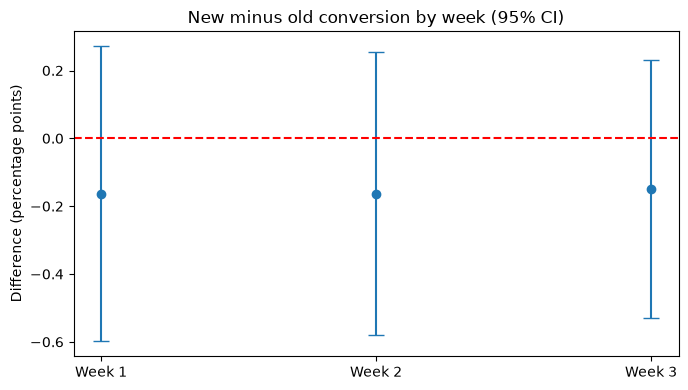

In [4]:
plt.figure(figsize=(7, 4))
plt.errorbar(weekly["week"], weekly["diff_pp"],
             yerr=[weekly["diff_pp"] - weekly["ci_low"], weekly["ci_high"] - weekly["diff_pp"]],
             fmt="o", capsize=6)
plt.axhline(0, color="red", linestyle="--")
plt.xticks([1, 2, 3], ["Week 1", "Week 2", "Week 3"])
plt.title("New minus old conversion by week (95% CI)")
plt.ylabel("Difference (percentage points)")
plt.tight_layout()
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/novelty_check.png", dpi=150)
plt.show()

In [5]:
seg.reset_index(names="segment").to_csv("outputs/segments.csv", index=False)